## Q-learning con Python

En este cuaderno vamos a implementar el algoritmo de aprendizaje por refuerzo Q-learning para resolver un entorno sencillo disponible con el paquete `gymnasium`.

Este problema, llamado [`Taxi Problem`](https://gymnasium.farama.org/environments/toy_text/taxi/), consiste en conducir un taxi para recoger pasajeros y llevarlos a su destino, en un pequeño mundo de 5x5.

## 1. Instalar e importar librerías

In [1]:
# Instalamos gymnasium
!pip install gymnasium

In [2]:
# Importamos las librerías necesarias
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import random
import tqdm
from time import time, sleep
from IPython.display import clear_output

%matplotlib inline
np.random.seed(21)

## 2. Descripción del entorno

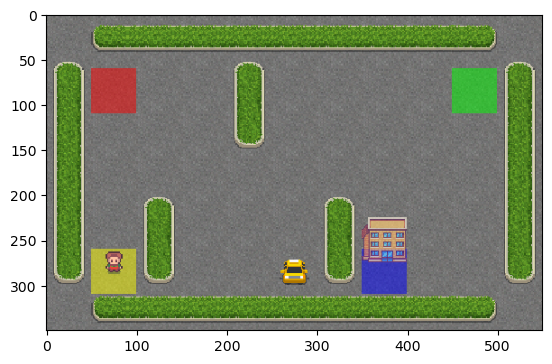

In [ ]:
# Inicializamos el entorno
env = gym.make("Taxi-v3", render_mode="rgb_array")
env.reset()

# Y lo visualizamos
plt.imshow(env.render())
plt.show()

En este entorno de 5x5 localizaciones, existen 4 posibles destinos y puntos de recogida: los espacios en azul, amarillo, verde o rojo.

El taxi comienza en una posición aleatoria, y el pasajero en uno de esos 4 puntos. El objetivo es mover el taxi a la posición del pasajero, recogerlo, conducir a su destino y dejarlo allí.

### Espacio de acciones

Existen 6 acciones posibles:

- 0: Mover abajo
- 1: Mover arriba
- 2: Mover a la derecha
- 3: Mover a la izquierda
- 4: Recoger al pasajero
- 5: Dejar al pasajero

Espacio de acciones:  Discrete(6)
Acción elegida:  0


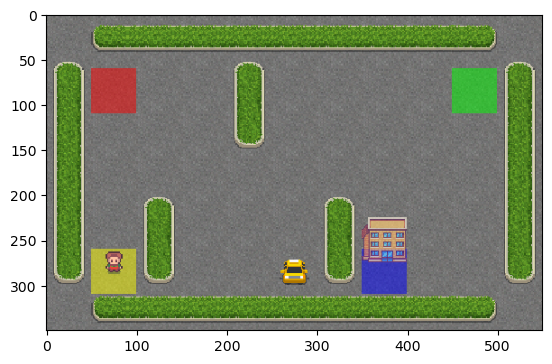

In [ ]:
# Espacio de acciones y elegir una acción al azar
print("Espacio de acciones: ", env.action_space)

a = env.action_space.sample()
print("Acción elegida: ", a)

# Ejecutamos la acción
info = env.step(a)

plt.imshow(env.render())
plt.show()

### Espacio de estados

Hay 500 posibles estados discretos distintos; que codifican las 25 localizaciones posibles del taxi, las 5 localizaciones posibles del pasajero (en uno de los 4 destinos o dentro del taxi) y los 4 posibles destinos.

En el entorno de gymnasium, cada estado se codifica como un número entre 0 y 499.

In [ ]:
print("Espacio de estados: ", env.observation_space)
print("Estado actual: ", info[0])

Espacio de estados:  Discrete(500)
Estado actual:  451


### Recompensas

La función de recompensa puede tomar los siguientes valores:

- +20 por dejar al pasajero en su destino.
- -10 por ejecutar las acciones "recoger" o "dejar" de forma ilegal.
- -1 por cada paso que se tarde en completar la tarea.

In [ ]:
print("Recompensa: ", info[1])

Recompensa:  -1


## 3. Agente aleatorio

Antes de implementar nuestro algoritmo de RL, vamos a ver el rendimiento de un agente que simplemente hace acciones de forma aleatoria.

In [3]:
def ejecutar_agente_aleatorio(num_episodios):
    """Implementa y ejecuta un agente aleatorio."""
    recompensas = []
    for ep in tqdm.tqdm(range(num_episodios)):
        # Inicializar el episodio
        info_episode = []  # para visualizar
        env.reset()
        done = False
        R = 0.0
        while not done:
            action = env.action_space.sample()  # Acción aleatoria
            new_state, reward, done, info, _ = env.step(action)
            R += reward
            info_episode.append(
                {
                    "action": action,
                    "reward": reward,
                    "frame": env.render(),
                }
            )
        recompensas.append(R)
    return recompensas, info_episode


def print_frames(frames, max_timesteps):
    """Función auxiliar para visualizar un episodio."""
    for i, frame in enumerate(frames[:max_timesteps]):
        clear_output(wait=True)
        plt.imshow(frame["frame"])
        plt.title(f"Timestep: {i + 1} | Action: {frame['action']} | Reward: {frame['reward']}")
        plt.show()
        plt.close()
        sleep(.2)

In [ ]:
recompensas, frames = ejecutar_agente_aleatorio(3)

print("Recompensa media: ", np.mean(recompensas))

100%|█████████████████████████████████████████████| 3/3 [00:15<00:00,  5.03s/it]

Recompensa media:  -6304.0


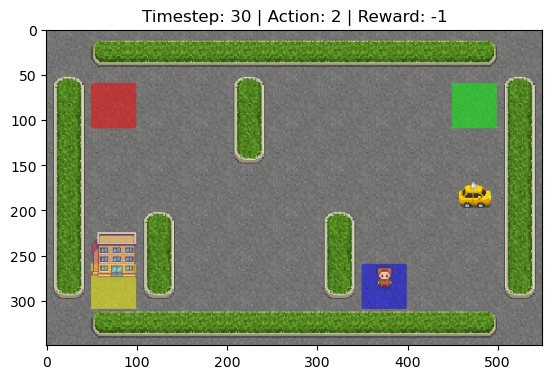

In [ ]:
print_frames(frames, 30)

## 4. Q-learning

A continuación vamos a implementar el algoritmo Q-learning.

La idea detrás de este algoritmo de RL es crear una tabla donde almacenemos los valores de la función de calidad para cada estado y acción, `Q(s,a)`, y actualizar estos valores conforme se recoge más información sobre los mismos.

También introducimos un hiperparámetro (`eps`) que determina la probabilidad de elegir una acción al azar. Esto hará que nuestro agente explore nuevas acciones, y ello pueda dar lugar a una política óptima.

In [4]:
def q_learning(num_episodios, gamma, alpha, eps):
    """Implementa el algoritmo Q-learning.

    La ecuación utilizada para actualizar los valores de la función Q es:

    `Q(s,a) = (1 - alpha) * Q(s,a) + alpha * (reward + gamma * max_a Q(s',a))``
    """

    # Inicializamos la matriz Q(s,a) con ceros
    Q_matriz = np.zeros([env.observation_space.n, env.action_space.n])

    rewards_totales = []
    for i in tqdm.tqdm(range(num_episodios)):
        state, _ = env.reset()
        R = 0.0
        done = False
        # Comienza el episodio
        while not done:
            # Escogemos una acción - aleatoria con probabilidad eps
            if random.uniform(0, 1) < eps:
                action = env.action_space.sample()
            else:
                action = np.argmax(Q_matriz[state])
            # Ejecutamos la acción
            new_state, reward, done, info, _ = env.step(action)
            R += reward

            # Actualizamos los valores de Q
            Q_actual = Q_matriz[state, action]
            next_Q_max = np.max(Q_matriz[new_state])

            Q_matriz[state, action] = (1 - alpha) * Q_actual + alpha * (reward + gamma * next_Q_max)

            state = new_state

        rewards_totales.append(R)

    return Q_matriz, rewards_totales

In [ ]:
# Entrenamos el algoritmo
Q_optima, rewards = q_learning(2000, 0.9, 0.1, 0.05)

100%|█████████████████████████████████████| 2000/2000 [00:01<00:00, 1685.74it/s]


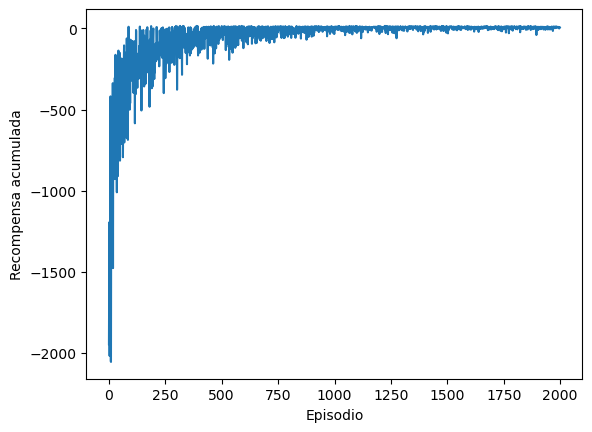

In [ ]:
# Visualizamos las rewards acumuladas durante el entrenamiento
plt.plot(rewards)
plt.xlabel("Episodio")
plt.ylabel("Recompensa acumulada")
plt.show()

Como vemos en el gráfico, el agente va mejorando su política y maximizando cada vez la recompensa acumulada en cada episodio.

Finalmente, vamos a utilizar la matriz Q(s,a) óptima para ejecutar el agente y evaluar su rendimiento.

In [ ]:
def ejecutar_agente(Q_matriz, num_episodios = 5):
    """Ejecuta un agente utilizando la matriz Q precomputada."""
    rewards_totales = []
    for i in tqdm.tqdm(range(num_episodios)):
        state, _ = env.reset()
        info_episodio = []  # para visualizar
        R = 0.0
        done = False
        while not done:
            action = np.argmax(Q_matriz[state])
            # Ejecutamos la acción
            new_state, reward, done, info, _ = env.step(action)

            R += reward
            state = new_state
            info_episodio.append(
                {
                    "action": action,
                    "reward": reward,
                    "frame": env.render(),
                }
            )

        rewards_totales.append(R)

    return rewards_totales, info_episodio

In [ ]:
rewards_totales, info_episodio = ejecutar_agente(Q_optima, 5)

print("Recompensa acumulada media: ", np.mean(rewards_totales))

100%|█████████████████████████████████████████████| 5/5 [00:00<00:00, 22.08it/s]

Recompensa acumulada media:  8.6


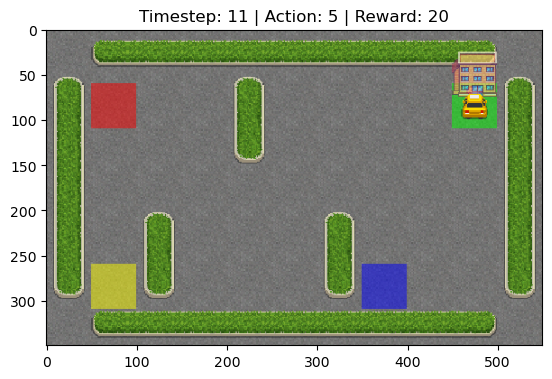

In [ ]:
print_frames(info_episodio, 20)

El agente consigue minimizar el número de timesteps necesarios para completar la tarea, y consigue llevar al pasajero a su destino correctamente.

Podemos concluir por tanto que el algoritmo Q-learning ha sido eficaz para resolver este entorno, en el cual el espacio de acciones y de estados no era muy grande.

La librería `gymnasium` tiene gran cantidad de entornos con los que se pueden probar diferentes algoritmos de aprendizaje por refuerzo. Los algoritmos sencillos como Q-learning no proporcionan buenos resultados cuando las acciones y/o los estados tienen de alta dimensionalidad (o incluso continuos). En ese caso, es necesario acudir al deep RL.